### Repository Setup

Clone the public CART repository and set the working directory to its root.

In [1]:
import os
import subprocess
from pathlib import Path

repo_dir = Path("/content/cart")

# Clone the repository or update an existing clone
if not repo_dir.exists():
    subprocess.run(
        ["git", "clone", "https://github.com/semoglou/cart.git", str(repo_dir)],
        check=True
    )
else:
    subprocess.run(
        ["git", "pull", "--ff-only", "origin", "main"],
        cwd=repo_dir,
        check=True
    )

os.chdir(repo_dir)

print("Working directory:", os.getcwd())
print(
    "Stopwords file exists:",
    Path("dataset/1_preparation/01_stopwords_all.txt").is_file()
)

Working directory: /content/cart
Stopwords file exists: True


In [2]:
from pathlib import Path
import zipfile

repo = Path("/content/cart")
dataset_dir = repo / "dataset"

print("Datasets in repository:\n")

for path in sorted(dataset_dir.rglob("*")):
    if path.is_file():
        print(path.relative_to(repo))

print("\nOriginal input dataset:")

original_dataset = (
    dataset_dir / "1_preparation" / "05_Tempi_pargraphs_clean.csv.zip"
)

if original_dataset.is_file():
    print("FOUND:", original_dataset.relative_to(repo))
    print(
        "File size (MB):",
        round(original_dataset.stat().st_size / (1024 ** 2), 2)
    )
    print("Valid ZIP:", zipfile.is_zipfile(original_dataset))
else:
    print("NOT FOUND:", original_dataset.relative_to(repo))

Datasets in repository:

dataset/1_preparation/01_paragraphs_clean.csv.zip
dataset/1_preparation/01_stopwords_all.txt
dataset/1_preparation/05_Tempi_paragraphs_clean.csv.zip
dataset/2_screening_extraction/02_cluster_metadata.csv
dataset/2_screening_extraction/02_clusters_with_titles.csv
dataset/2_screening_extraction/02_dataset_clustered.csv.zip
dataset/2_screening_extraction/03_tempi_df_dataset.csv
dataset/2_screening_extraction/04_tempi_df_R1_narratives.csv
dataset/2_screening_extraction/05_tempi_df_R1_extra_narratives.csv
dataset/2_screening_extraction/05_tempi_df_R1_invalid_jsons.csv
dataset/2_screening_extraction/06_tempi_df_R1_final_narratives.csv
dataset/2_screening_extraction/par_embeddings.npy
dataset/3_narrative_taxonomy/narrative_embeddings.npy
dataset/3_narrative_taxonomy/narrative_taxonomy_ksil.csv

Original input dataset:
NOT FOUND: dataset/1_preparation/05_Tempi_pargraphs_clean.csv.zip


## Stopwords Preparation

**Define and Combine Greek Stopwords**

This cell combines a manually curated list of parliamentary stopwords with the Greek stopwords provided by NLTK. Duplicate entries are removed, and all terms are converted to lowercase.

The original implementation is preserved and remains enabled.

In [3]:
parliament_stopwords = [
    "αιθουσα","ακριβως","ακομη","αλλη","αλλες","αλλο","απο","αποφαση","αποφαση",
    "αποτελει","αποφαση","απο","απο","αρθρα","αρθρο","αρθρου","αρθρα","αρα",
    "αρχη","αρχας","αφηστε","βημα","βεβαια","βεβαιως","για","γενικα","γινει",
    "γινεται","γνωμη","γρηγορα","δεκα","δεκαπεντε","δεν","δευτερολογια",
    "δευτερολεπτα","δηλαδη","δηθεν","διαδικασια","διαδικασιας","διαφορετικο",
    "δικαιου","διοτι","δυο","εαυτο","εαν","εγινε","εγω","εδειξε","εδω","εε",
    "ειναι","ειναι","ειπα","ειπατε","ειπα","ειπατε","ειπε","ειπε","ειτε",
    "εκείνος","εκει","εκεινο","εκεινος","εκτος","εμας","εμενα","εν","ενας",
    "ενταξει","ενω","ενω","εντελει","εντος","εξαιρεση","εξει","επανω","επειδη",
    "επειτα","επι","επισης","επιτρεψτε","εργο","ερχεται","ερωτηση","εσας",
    "εσεις","εστι","εστω","ετερο","ευαισθησια","ευχαριστω","ευχαριστουμε",
    "ζητημα","ζητημα","ζωη","η","ηταν","ηθελα","ηρθε","θαρρος","θεμα","θελω",
    "θελουμε","θεσεις","θεση","ισως","ισως","καθολου","καθως","και","καλα",
    "κανει","κανουμε","κανετε","κανω","καμμια","κανουμε","καποια","καποιο",
    "καποιοι","καποιος","καποιο","καποιο","καποιοι","καποιον","καποιος",
    "καποιος","καποιος","καποιο","καποιο","καποιοι","καποιος","καποιο",
    "καποιοι","κατι","κατα","καταθεσαμε","καταθεσω","καταθετει","καταθετω",
    "καταθετουμε","καταρχας","καταρχην","κατασταση","κατι","κατ","κατ’",
    "κατηγορια","καθοτι","καθως","κατι","κατω","κε","κεντρο","κοιταξτε",
    "κοντα","κοιταξτε","κυριε","κυρια","κυριες","κυριοι","κυριος","κυριος",
    "λεει","λεμε","λεω","λετε","λεπτο","λεπτα","λιγο","λοιπον","λογω","λογος",
    "μα","μαλιστα","μας","μας","με","μεγαλο","μεγαλυτερη","μεγαλυτερο",
    "μεχρι","μερες","μερη","μεσα","μεσω","μετα","μεταξυ","μην","μιλαμε",
    "μιλατε","μιλησει","μιλησω","μιλησε","μονο","μου","μπορει","μπορουμε",
    "να","ναι","νεο","νομιζω","νομοσχεδιου","νυν","ξανα","ξεκινησω","ξερω",
    "ο","οπως","οποια","οποιες","οποιο","οποιοδηποτε","οποιον","οποιος",
    "οποτε","οριστε","οσο","οσον","οσοι","οτι","οτιδηποτε","οχι","ομως",
    "οποτε","οποιος","οποια","οποιο","οποιες","οποιον","οποιος","οποιος",
    "οποιος","οποιοδηποτε","οποιος","οποιες","οποιων","οπου","οταν","οτι",
    "οτιδηποτε","οτως","ουσιαστικα","παλι","παμε","παντως","παντως",
    "παρα","παρακαλω","παραγραφοι","παραγραφου","παραγραφος","παραπανω",
    "παρασκευη","παρακατω","παρων","παση","πει","πειτε","περα","περα",
    "περι","περιπου","πηγαινει","πιο","πλεον","πλειονα","πλεονεκτημα",
    "πληρως","ποια","ποιο","ποιοι","ποιος","πολυ","πολλα","πολλες","πολλους",
    "ποσο","πραγματι","πραγματικα","πραγματα","πρακτικα","πριν","προς",
    "προκειται","προσ","προσφατα","προτεινω","προταση","προβλεπεται",
    "προβλημα","πρωτα","πωσ","πως","πωσ","ρωτω","σαραντα","σαφως","σε","σενα",
    "σας","σας","σου","σου","συναδελφε","συναδελφεσ","συναδελφοι","σωμα",
    "τα","ταδε","ταξη","ταξι","τελικα","τελικως","τελος","τετοιο","τη",
    "την","τι","τιποτα","τις","το","τον","τοτε","τροπολογια","τροπολογιες",
    "τρεις","τρια","τριαντα","των","τωρα","υπαρχει","υπαρχουν","υπουργε",
    "υπο","υπηρεσιων","ωστε","χωρις"
]



# Combine with nltk Greek stopwords
from nltk.corpus import stopwords
import nltk
nltk.download('stopwords')

greek_stopwords = stopwords.words('greek')
stopwords_all = list(set(greek_stopwords + parliament_stopwords))
stopwords_all = [w.lower() for w in stopwords_all]  # ensure lowercase consistency

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.


**Normalize Greek Stopwords**

This cell normalizes the combined Greek stopwords by removing diacritics (including tonos), converting terms to lowercase, and removing duplicates.

The normalized stopwords are stored as a set for efficient lookup during text preprocessing.

The original implementation is preserved and remains enabled.

In [4]:
import unicodedata

def normalize_greek(text):
    """
    Removes tonos/diacritics from a Greek word.
    Safe for stopword normalization.
    """
    # Convert to NFD (base letter + combining marks)
    text = unicodedata.normalize("NFD", text)
    # Remove combining marks (tonos, diaeresis, etc.)
    text = "".join(c for c in text if unicodedata.category(c) != "Mn")
    # Recompose (NFC)
    return unicodedata.normalize("NFC", text)


# 1. Read stopwords (already loaded into stopwords_all)
# Make sure they are clean strings
stopwords_all = [w.strip().lower() for w in stopwords_all if isinstance(w, str) and w.strip()]
# 2. Normalize each stopword (remove tonos)
stopwords = [normalize_greek(w) for w in stopwords_all]
# 3. Make stopwords a set (fast lookups)
stopwords = set(stopwords)

# Preview
print("Original:", stopwords_all[:10])
print("Normalized:", list(stopwords)[:10])

Original: ['με', 'οσο', 'μεγαλυτερο', 'εξει', 'ὑπέρ', 'ὃς', 'ερχεται', 'εαν', 'τισ', 'τροπολογιες']
Normalized: ['με', 'οσο', 'μεγαλυτερο', 'εξει', 'εις', 'ερχεται', 'εαν', 'δια', 'τισ', 'ουδεισ']


**Save Prepared Stopwords**

**Original Implementation — Execution disabled by default**

This cell exports the normalized Greek stopwords to `01_stopwords_all.txt`.

The original export logic is preserved for reproducibility. The published stopwords file is already available in the repository and is loaded in the following cell.

In [5]:
"""
with open('./out_files/01_stopwords_all.txt', 'w', encoding='utf-8') as f:
    for item in stopwords:
        f.write("%s\n" % item)
"""

'\nwith open(\'./out_files/01_stopwords_all.txt\', \'w\', encoding=\'utf-8\') as f:\n    for item in stopwords:\n        f.write("%s\n" % item)\n'

**Load Published Stopwords**

This cell loads the published normalized Greek stopwords from the CART repository, ensuring that subsequent processing uses the same stopwords as the original study.

In [6]:
from pathlib import Path

stopwords_path = Path(
    './dataset/1_preparation/01_stopwords_all.txt'
)

with open(stopwords_path, 'r', encoding='utf-8') as f:
    stopwords = {line.strip() for line in f if line.strip()}

print(f"Published stopwords loaded: {len(stopwords)}")

Published stopwords loaded: 428


# Import and Cleansing of dataset

**Load Original Parliamentary Dataset**

This cell loads the original parliamentary dataset from the public CART repository.

The dataset is distributed as a compressed CSV file. The original preprocessing pipeline remains enabled.

In [7]:
import pandas as pd

# Load the original parliamentary dataset from the repository
dataframe = pd.read_csv(
    './dataset/1_preparation/05_Tempi_paragraphs_clean.csv.zip',
    compression='zip',
    encoding='utf-8'
)

print("Loaded dataset:", dataframe.shape)

display(dataframe.head(3))

Loaded dataset: (216396, 14)


,member_name,sitting_date,parliamentary_period,parliamentary_session,parliamentary_sitting,political_party,government,member_region,roles,member_gender,speaker_info,speech_id,paragraph_id,paragraph
0,τασουλας αναστασιου κωνσταντινος,07/03/2023,period 18 presided parliamentary republic,session 4,sitting 83,νεα δημοκρατια,['\nμητσοτακη κυριακου\n(08/07/2019-25/05/2023)'],ιωαννινων,['προεδρος βουλης(18/07/2019-28/05/2023)'],male,προεδρος,2023-03-07_1_0,2023-03-07_1_0_p1,"Κυρίες και κύριοι συνάδελφοι, αρχίζει η συνεδρ..."
1,αθανασιου χριστοφα χαραλαμπος,07/03/2023,period 18 presided parliamentary republic,session 4,sitting 83,νεα δημοκρατια,['\nμητσοτακη κυριακου\n(08/07/2019-25/05/2023)'],λεσβου,['β αντιπροεδρος βουλης(18/07/2019-28/05/2023)'],male,προεδρευων,2023-03-07_1_2,2023-03-07_1_2_p1,"Κυρίες και κύριοι συνάδελφοι, έχω την τιμή να ..."
2,αθανασιου χριστοφα χαραλαμπος,07/03/2023,period 18 presided parliamentary republic,session 4,sitting 83,νεα δημοκρατια,['\nμητσοτακη κυριακου\n(08/07/2019-25/05/2023)'],λεσβου,['β αντιπροεδρος βουλης(18/07/2019-28/05/2023)'],male,προεδρευων,2023-03-07_1_2,2023-03-07_1_2_p2,"Επίσης, οι Υπουργοί Περιβάλλοντος και Ενέργεια..."


In [9]:
# Convert the column to datetime objects
dataframe['sitting_date'] = pd.to_datetime(dataframe['sitting_date'], format='%d/%m/%Y')

# Convert the datetime objects to month periods (YYYY-MM)
dataframe['sitting_date'] = dataframe['sitting_date'].dt.to_period('M').astype(str)

# Remove Irrelevant Columns
df_clean = dataframe.drop(columns=['member_region','parliamentary_period' ,'parliamentary_session',
                                            'parliamentary_sitting','roles','government'])
# Preview Cleaned Dataset

df_clean.head(3)

,member_name,sitting_date,political_party,member_gender,speaker_info,speech_id,paragraph_id,paragraph
0,τασουλας αναστασιου κωνσταντινος,2023-03,νεα δημοκρατια,male,προεδρος,2023-03-07_1_0,2023-03-07_1_0_p1,"Κυρίες και κύριοι συνάδελφοι, αρχίζει η συνεδρ..."
1,αθανασιου χριστοφα χαραλαμπος,2023-03,νεα δημοκρατια,male,προεδρευων,2023-03-07_1_2,2023-03-07_1_2_p1,"Κυρίες και κύριοι συνάδελφοι, έχω την τιμή να ..."
2,αθανασιου χριστοφα χαραλαμπος,2023-03,νεα δημοκρατια,male,προεδρευων,2023-03-07_1_2,2023-03-07_1_2_p2,"Επίσης, οι Υπουργοί Περιβάλλοντος και Ενέργεια..."


In [10]:
# First, remove rows where 'political_party' is 'βουλη'
df_clean = df_clean[df_clean['political_party'] != 'βουλη']

# Next, define the list of 'speaker_info' values to be removed
speakers_to_remove = [
    'προεδρευων',
    'βουλευτης/ες',
    'προεδρος',
    'υφυπουργος κλιματικης κρισης και πολιτικης προστασιας ακουσα και σας απαντω, κυρια αντωνιου…προεδρευων χαραλαμπος αθανασιου',
    'ναντια'
]

# Then, remove rows where 'speaker_info' is one of the values in the list
df_clean = df_clean[~df_clean['speaker_info'].isin(speakers_to_remove)]
df_clean = df_clean.drop(columns=['speaker_info'])

df_clean.info()

<class 'pandas.core.frame.DataFrame'>
Index: 158891 entries, 9 to 216389
Data columns (total 7 columns):
 #   Column           Non-Null Count   Dtype 
---  ------           --------------   ----- 
 0   member_name      158891 non-null  object
 1   sitting_date     158891 non-null  object
 2   political_party  158891 non-null  object
 3   member_gender    158891 non-null  object
 4   speech_id        158891 non-null  object
 5   paragraph_id     158891 non-null  object
 6   paragraph        158891 non-null  object
dtypes: object(7)
memory usage: 9.7+ MB


In [11]:
import re
import unicodedata

def clean_speech(text):
    """
    Greek text cleaning without stress.
    - Keeps Greek letters
    - Removes accents/stress
    - Keeps numbers
    - Removes punctuation
    - Normalizes whitespace
    - Safe for messy Unicode from parliamentary transcripts
    """

    if not isinstance(text, str):
        return ""

    # 1. Normalize to NFD (separates base letters + accents)
    text = unicodedata.normalize("NFD", text)
    # 2. Remove diacritics/stress (Mn = non-spacing mark)
    text = "".join([c for c in text if unicodedata.category(c) != "Mn"])
    # 3. Normalize back to NFC
    text = unicodedata.normalize("NFC", text)
    # 4. Lowercase
    text = text.lower()
    # 5. Keep Greek letters + Latin letters + numbers
    text = re.sub(r"[^a-zA-Z0-9α-ωΑ-Ω\s]", " ", text)
    # 6. Collapse multiple spaces
    text = re.sub(r"\s+", " ", text).strip()

    return text



df_clean["par_clean"] = df_clean["paragraph"].astype(str).apply(clean_speech)
df_clean = df_clean[df_clean["par_clean"].str.strip().str.len() > 100]

In [12]:
print (f'Original Dataset: {dataframe.shape}\n Cleaned Dataset: {df_clean.shape}')

Original Dataset: (216396, 14)
 Cleaned Dataset: (117716, 8)


## Normalize Parties

In [13]:
def normalize_party(name):
    name = name.strip().lower()
    if "νεα δημοκρατια" in name or "εξωκοινοβουλευτικός" in name:
        return "Nea Dimokratia"
    elif "συνασπισμος ριζοσπαστικης αριστερας - προοδευτικη συμμαχια"  in name or 'συνασπισμος ριζοσπαστικης αριστερας' in name:
        return "SYRIZA-PS"
    elif "νεα αριστερα" in name:
        return "Nea Aristera"
    elif "κινημα αλλαγης" in name or "πανελληνιο σοσιαλιστικο κινημα - κινημα αλλαγης" in name:
        return "PASOK-KINAL"
    elif "πλευση ελευθεριας - ζωη κωνσταντοπουλου" in name:
        return "Plefsi Eleftherias"
    elif "κομμουνιστικο κομμα ελλαδας" in name:
        return "KKE"
    elif "ελληνικη λυση - κυριακος βελοπουλος" in name:
        return "Elliniki Lysi"
    elif 'δημοκρατικο πατριωτικο κινημα "νικη"' in name:
        return "Niki"
    elif "σπαρτιατες" in name:
        return "Spartiates"
    elif "ανεξαρτητοι (εκτος κομματος)" in name:
        return "Independents"
    elif "μετωπο ευρωπαικης ρεαλιστικης ανυπακοης (μερα25)" in name:
        return "MeRA25"
    else:
        return name.title()

df_clean.insert(1, "party", df_clean["political_party"].apply(normalize_party))
df_clean.drop(columns=["political_party"], inplace=True)


print(df_clean["party"].value_counts())

party
Nea Dimokratia        43404
SYRIZA-PS             14174
PASOK-KINAL           13688
KKE                    9509
Plefsi Eleftherias     9351
Elliniki Lysi          8677
Nea Aristera           6071
Niki                   5451
Spartiates             4148
Independents           2875
MeRA25                  368
Name: count, dtype: int64


In [14]:
df_clean.head(5)

,member_name,party,sitting_date,member_gender,speech_id,paragraph_id,paragraph,par_clean
9,κελετσης δημητριου σταυρος,Nea Dimokratia,2023-03,male,2023-03-07_1_4,2023-03-07_1_4_p1,"Ευχαριστώ, κύριε Πρόεδρε. Κύριε Πρόεδρε, εκφρά...",ευχαριστω κυριε προεδρε κυριε προεδρε εκφραζω ...
10,κελετσης δημητριου σταυρος,Nea Dimokratia,2023-03,male,2023-03-07_1_4,2023-03-07_1_4_p2,"Απέναντι σε αυτά τα παιδιά, τα θύματα αυτής τη...",απεναντι σε αυτα τα παιδια τα θυματα αυτης της...
11,κελετσης δημητριου σταυρος,Nea Dimokratia,2023-03,male,2023-03-07_1_4,2023-03-07_1_4_p3,"Κυρίες και κύριοι συνάδελφοι, εισερχόμενος στη...",κυριες και κυριοι συναδελφοι εισερχομενος στη ...
12,κελετσης δημητριου σταυρος,Nea Dimokratia,2023-03,male,2023-03-07_1_4,2023-03-07_1_4_p4,Η εμπέδωση αισθήματος λειτουργίας κράτους δικα...,η εμπεδωση αισθηματος λειτουργιας κρατους δικα...
13,κελετσης δημητριου σταυρος,Nea Dimokratia,2023-03,male,2023-03-07_1_4,2023-03-07_1_4_p5,Εκσυγχρονίζεται η διοικητική δικαιοσύνη με τη ...,εκσυγχρονιζεται η διοικητικη δικαιοσυνη με τη ...


In [15]:
df_clean['member_gender'].value_counts()

,count
member_gender,
male,91142
female,26574


In [16]:
import os
os.makedirs('./out_files', exist_ok=True)

df_clean.to_csv('./out_files/01_paragraphs_clean.csv', index=False, encoding="utf-8-sig")

# Plots

In [17]:
import pandas as pd

# Original implementation — disabled
"""
df = pd.read_csv('./out_files/01_paragraphs_clean.csv', encoding="utf-8-sig")
print(df.shape)
"""

# Load the published preprocessed dataset
df = pd.read_csv(
    './dataset/1_preparation/01_paragraphs_clean.csv.zip',
    compression='zip',
    encoding='utf-8-sig'
)

print("Published dataset:", df.shape)

Published dataset: (117716, 8)


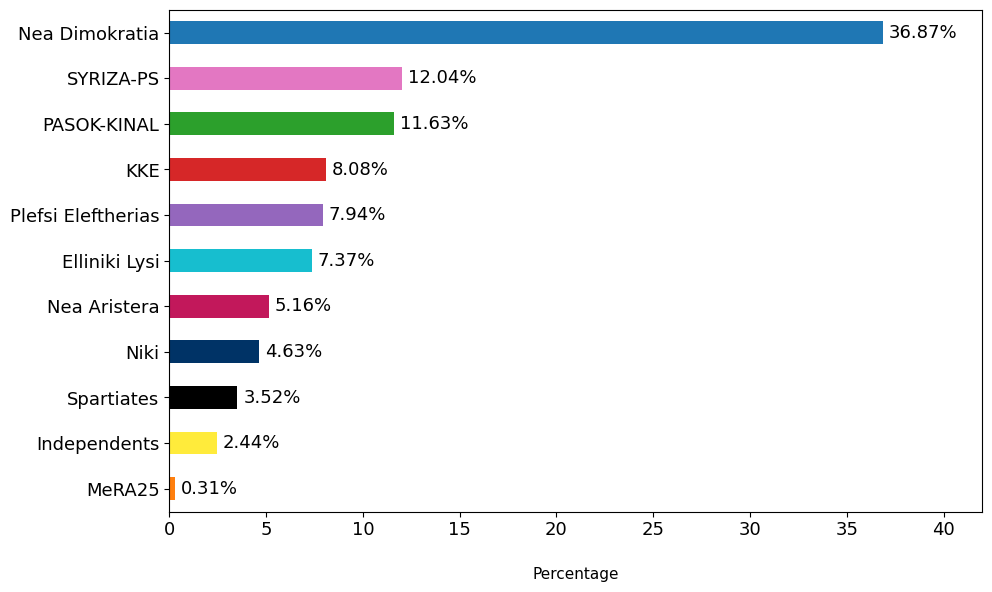

In [18]:
import os
import matplotlib.pyplot as plt

os.makedirs("./out_files/plots/", exist_ok=True)

# Compute percentages
party_percent = (
    df["party"].value_counts(normalize=True) * 100
).round(2)

# Define consistent colors per party
colors = {
    "Nea Dimokratia": "#1f77b4",
    "SYRIZA-PS": "#e377c2",
    "Nea Aristera": "#c2185b",
    "PASOK-KINAL": "#2ca02c",
    "Plefsi Eleftherias": "#9467bd",
    "KKE": "#d62728",
    "Elliniki Lysi": "#17becf",
    "Niki": "#003366",
    "Spartiates": "#000000",
    "Independents": "#ffeb3b",
    "MeRA25": "#ff7f0e"
}

# Plot
fig, ax = plt.subplots(figsize=(10, 6))

party_percent.plot(
    kind="barh",
    color=[colors.get(p, "#555555") for p in party_percent.index],
    ax=ax
)
ax.tick_params(axis='y', labelsize=13)
ax.tick_params(axis='x', labelsize=13) # Optional: adjust x-axis ticks to match


# Add labels outside bars
for i, v in enumerate(party_percent):
    ax.text(v + 0.3, i, f"{v:.2f}%", va='center', fontsize=13)

plt.xlabel("Percentage", fontsize=11, labelpad=20)
plt.ylabel("")
plt.gca().invert_yaxis()
ax.set_xlim(0, 42)  # stretch x-axis to 45%
plt.tight_layout(pad=1)
plt.savefig('./out_files/plots/corpus_split_per_party.jpg', bbox_inches='tight', dpi=500)
plt.show()



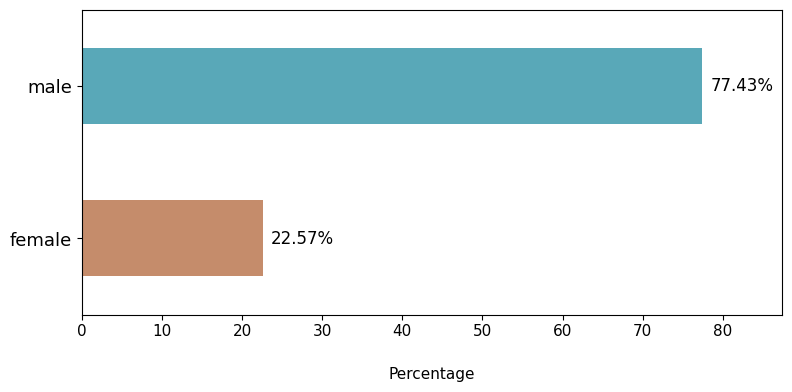

In [19]:
import os
import matplotlib.pyplot as plt

# Compute percentages
gender_percent = (
    df["member_gender"].value_counts(normalize=True) * 100
).round(2)

# Define consistent colors per gender
# Note: Adjust the keys ("male", "female")
gender_colors = {
    "male": "#59a8b8",  # Blue
    "female": "#c58c6b", # Pink

}

# Plot - using a shorter height (4 instead of 6) since there are fewer categories
fig, ax = plt.subplots(figsize=(8, 4))

gender_percent.plot(
    kind="barh",
    color=[gender_colors.get(g, "#555555") for g in gender_percent.index],
    ax=ax
)

ax.tick_params(axis='y', labelsize=13)
ax.tick_params(axis='x', labelsize=11) # Optional: adjust x-axis ticks to match

# Add labels outside bars
for i, v in enumerate(gender_percent):
    ax.text(v + 1.0, i, f"{v:.2f}%", va='center', fontsize=12)

plt.xlabel("Percentage", fontsize=11, labelpad=20)
plt.ylabel("", fontsize=11)
plt.gca().invert_yaxis()

# Dynamically set the x-axis limit to be slightly larger than the maximum value
ax.set_xlim(0, gender_percent.max() + 10)

plt.tight_layout(pad=1)
plt.savefig('./out_files/plots/corpus_split_per_gender.jpg', bbox_inches='tight', dpi=500)
plt.show()

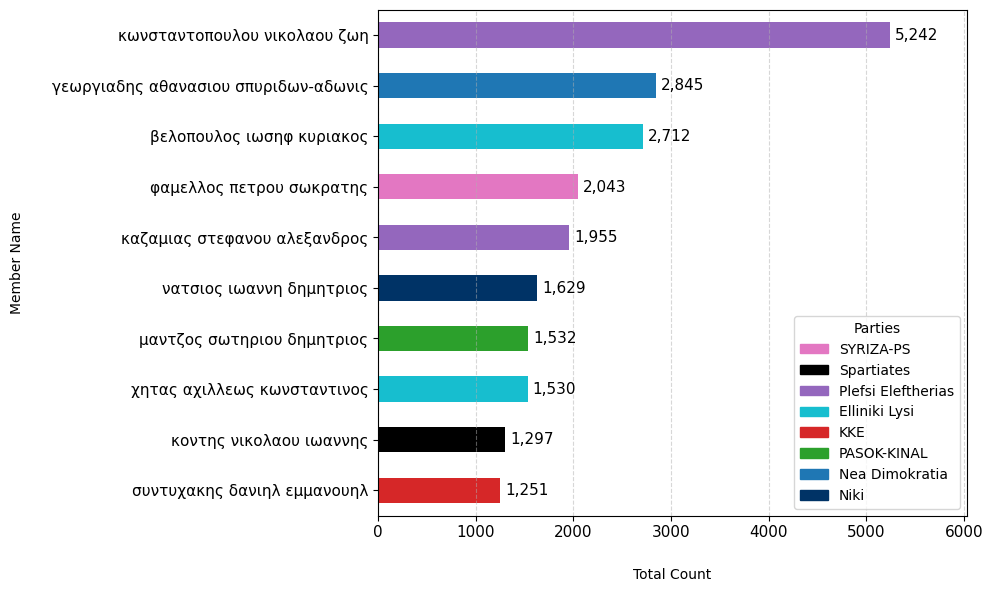

In [20]:
import os
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches


# 1. Define your party colors again
party_colors = {
    "Nea Dimokratia": "#1f77b4",
    "SYRIZA-PS": "#e377c2",
    "Nea Aristera": "#c2185b",
    "PASOK-KINAL": "#2ca02c",
    "Plefsi Eleftherias": "#9467bd",
    "KKE": "#d62728",
    "Elliniki Lysi": "#17becf",
    "Niki": "#003366",
    "Spartiates": "#000000",
    "Independents": "#ffeb3b",
    "MeRA25": "#ff7f0e"
}

# 2. Get the top 10 members by total count
top_members = df["member_name"].value_counts().head(10)

# 3. Create a lookup dictionary mapping each member to their party
# We drop duplicates to just get one clean pairing per member
member_to_party = (
    df.drop_duplicates(subset=['member_name'])
    .set_index('member_name')['party']
    .to_dict()
)


# 4. Generate the color list for the bars based on the member's party
bar_colors = []
for member in top_members.index:
    party = member_to_party.get(member, "Unknown")
    # If the party isn't in our dictionary, default to gray (#555555)
    color = party_colors.get(party, "#555555")
    bar_colors.append(color)

# 5. Plot
fig, ax = plt.subplots(figsize=(10, 6))

top_members.plot(
    kind="barh",
    color=bar_colors,
    ax=ax
)

# Add labels outside bars (using actual counts)
offset = top_members.max() * 0.01
for i, v in enumerate(top_members):
    ax.text(v + offset, i, f"{v:,}", va='center', fontsize=11)

# 6. Optional: Create a custom legend so people know what the colors mean!
# We only create legend entries for the parties that actually appear in the top 10
parties_in_top_10 = set([member_to_party.get(member) for member in top_members.index])
legend_handles = [
    mpatches.Patch(color=party_colors.get(p, "#555555"), label=p)
    for p in parties_in_top_10 if p in party_colors
]
ax.legend(handles=legend_handles, title="Parties", loc="lower right")
ax.tick_params(axis='y', labelsize=11)
ax.tick_params(axis='x', labelsize=11) # Optional: adjust x-axis ticks to match
# Final Formatting
plt.xlabel("Total Count", fontsize=10, labelpad=20)
plt.ylabel("Member Name", fontsize=10, labelpad=20)
plt.grid(axis='x', linestyle='--', alpha=0.5)

# Keep the highest value at the top``
plt.gca().invert_yaxis()

# Dynamically set the x-axis limit so the text labels aren't cut off
ax.set_xlim(0, top_members.max() * 1.15)

plt.tight_layout(pad=1)
plt.savefig('./out_files/plots/top_10_members.jpg', bbox_inches='tight', dpi=500)
plt.show()

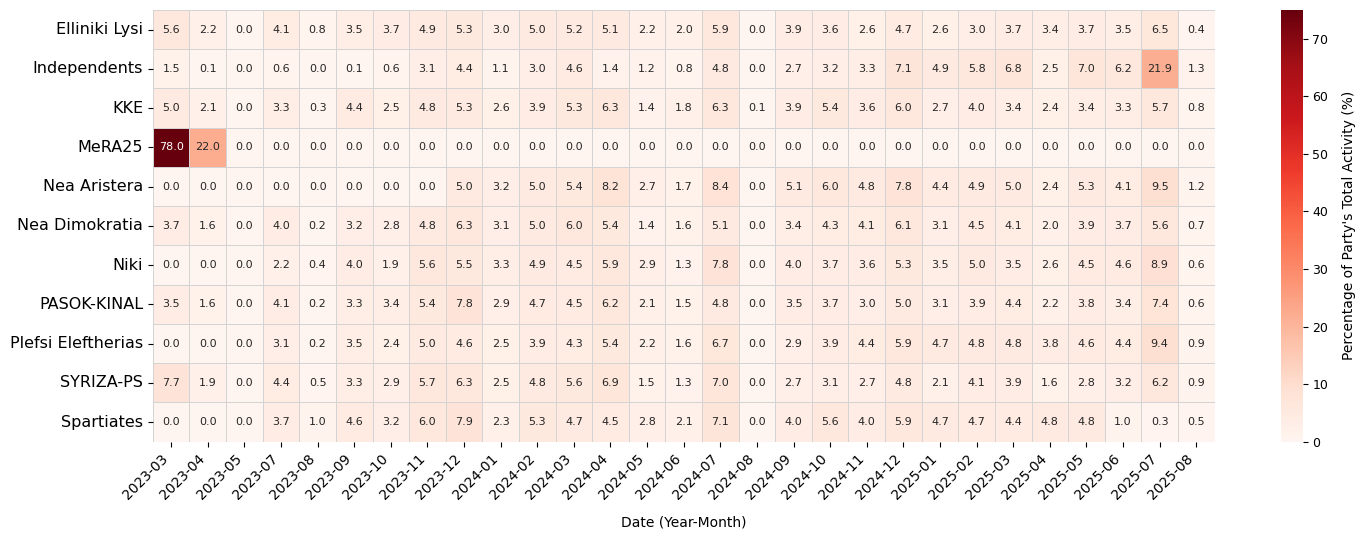

In [21]:
import os
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

os.makedirs("./out_files/plots/", exist_ok=True)

# 2. Create a cross-tabulation and normalize it
heatmap_data = pd.crosstab(
    df['party'],
    df['sitting_date'],
    normalize='index'
) * 100

# 3. Plot the heatmap
# Reduced figsize so it doesn't shrink massively when inserted into a LaTeX document
fig, ax = plt.subplots(figsize=(15, 5.5))

sns.heatmap(
    heatmap_data,
    cmap="Reds",
    vmin=0,
    vmax=75,
    linewidths=0.5,
    linecolor='lightgray',
    annot=True,
    fmt=".1f",
    ax=ax,
    annot_kws={"size": 8}, # Reduced so text fits inside smaller boxes
)

# --- Grab the colorbar and adjust for LaTeX ---
cbar = ax.collections[0].colorbar
cbar.ax.tick_params(labelsize=9)
cbar.set_label("Percentage of Party's Total Activity (%)", size=10, labelpad=10)

# 4. Formatting the plot
plt.xlabel("Date (Year-Month)", fontsize=10, labelpad=10)
plt.ylabel("")

# Rotate x-axis labels and adjust sizes for standard print reading
plt.xticks(rotation=45, ha='right', fontsize=10)
plt.yticks(fontsize=11.5)

plt.tight_layout()

# --- CRITICAL FOR OVERLEAF: Save as PDF ---
# Removed dpi=500 because PDFs are vector format and inherently infinite resolution
plt.savefig('./out_files/plots/normalized_party_activity_heatmap.pdf')
plt.show()